<a href="https://colab.research.google.com/github/Hackathon-D-Group-2026/Hackathon_D_Group_2026/blob/main/Untitled11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
train = pd.read_csv('/content/dataset_A_training.csv')
test = pd.read_csv('/content/dataset_A_testing.csv')

# Display dataset dimensions
print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

# Display first five records
display(train.head())


Training dataset shape: (4756, 31)
Testing dataset shape: (4749, 30)


,respondent_id,flu_concern,flu_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,seasonal_vaccine
0,1,2.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,0.0,0.0,entertainment,0,0
1,2,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,Rent,Employed,"MSA, Principle City",1.0,0.0,education,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,...,"> $75,000",Married,Own,Not in Labor Force,"MSA, Not Principle City",1.0,0.0,NaN,0,0
3,4,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",1.0,2.0,utilities,0,1
4,5,2.0,2.0,0.0,1.0,0.0,1.0,1.0,1.0,1.0,...,Below Poverty,Not Married,Rent,Not in Labor Force,"MSA, Not Principle City",2.0,0.0,NaN,1,0


2. Understand the variables

In [2]:

# Display column names
print("Columns in training dataset:")
for column in train.columns:
    print(column)

# Check data types
print("\nData types:")
print(train.dtypes)

# Dataset information
print("\nDataset information:")
train.info()


Columns in training dataset:
respondent_id
flu_concern
flu_knowledge
behavioral_antiviral_meds
behavioral_avoidance
behavioral_face_mask
behavioral_wash_hands
behavioral_large_gatherings
behavioral_outside_home
behavioral_touch_face
doctor_recc_seasonal
child_under_6_months
health_worker
health_insurance
opinion_seas_vacc_effective
opinion_seas_risk
opinion_seas_sick_from_vacc
age_group
education
race
sex
income_poverty
marital_status
rent_or_own
employment_status
census_msa
household_adults
household_children
employment_sector
number_chronic_med_conditions
seasonal_vaccine

Data types:
respondent_id                      int64
flu_concern                      float64
flu_knowledge                    float64
behavioral_antiviral_meds        float64
behavioral_avoidance             float64
behavioral_face_mask             float64
behavioral_wash_hands            float64
behavioral_large_gatherings      float64
behavioral_outside_home          float64
behavioral_touch_face            floa

3. Check missing values

,Missing_Count,Missing_Percentage
employment_sector,2314,48.65
health_insurance,1925,40.48
income_poverty,790,16.61
rent_or_own,381,8.01
doctor_recc_seasonal,321,6.75
education,270,5.68
employment_status,269,5.66
marital_status,265,5.57
child_under_6_months,152,3.20
health_worker,149,3.13


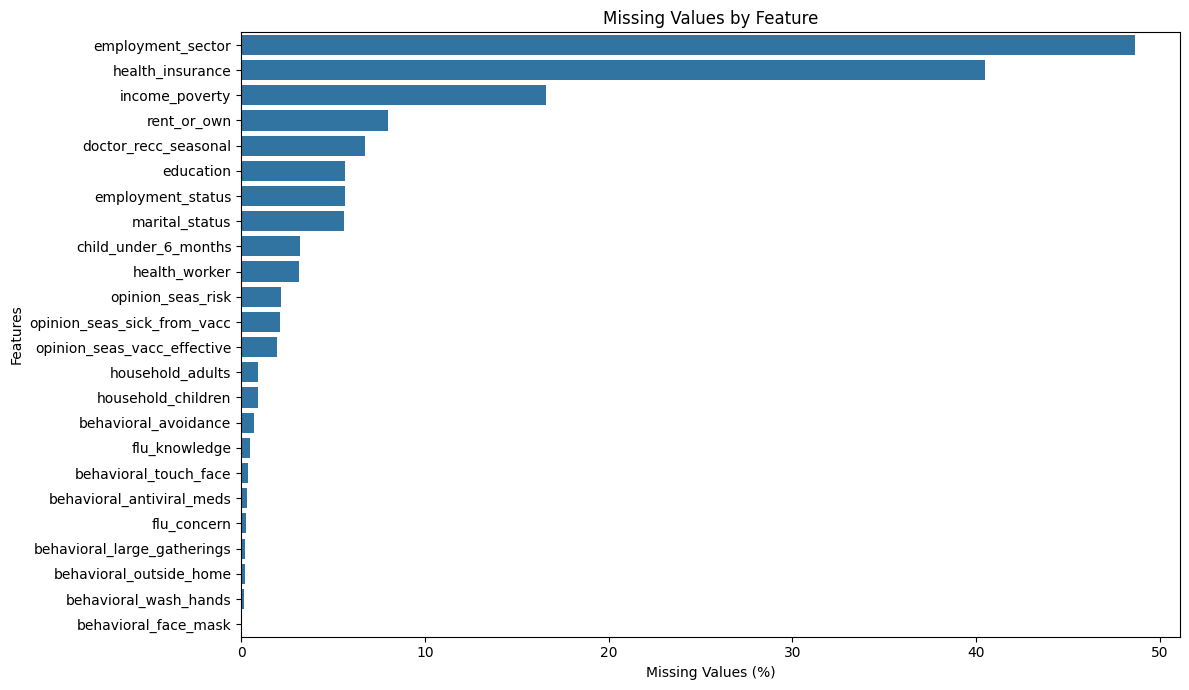

In [3]:

# Calculate missing values
missing = pd.DataFrame({
    'Missing_Count': train.isnull().sum(),
    'Missing_Percentage': train.isnull().mean() * 100
})

# Display only columns containing missing values
missing = missing[missing['Missing_Count'] > 0]

missing = missing.sort_values(
    by='Missing_Percentage',
    ascending=False
)

display(missing.round(2))

# Visualise missing values
plt.figure(figsize=(12, 7))

sns.barplot(
    x=missing['Missing_Percentage'],
    y=missing.index
)

plt.title('Missing Values by Feature')
plt.xlabel('Missing Values (%)')
plt.ylabel('Features')
plt.tight_layout()
plt.show()


4. Understand the target variable
Our target is seasonal_vaccine.
- 0 = Not vaccinated.
- 1 = Vaccinated.

seasonal_vaccine
1    2551
0    2205
Name: count, dtype: int64

Target percentages:
seasonal_vaccine
1    53.637511
0    46.362489
Name: proportion, dtype: float64


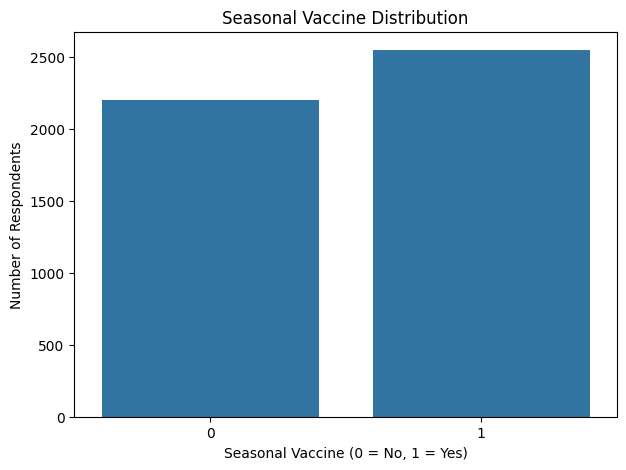

In [4]:

# Target distribution

print(train['seasonal_vaccine'].value_counts())

print("\nTarget percentages:")
print(
    train['seasonal_vaccine']
    .value_counts(normalize=True) * 100
)

# Plot target distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train,
    x='seasonal_vaccine'
)

plt.title('Seasonal Vaccine Distribution')
plt.xlabel('Seasonal Vaccine (0 = No, 1 = Yes)')
plt.ylabel('Number of Respondents')

plt.show()
